In [1]:

import platform
import sys

print("Python version:", sys.version)
print("Processor:", platform.machine())

try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("MPS available:", torch.backends.mps.is_available())
    print("CUDA available:", torch.cuda.is_available())
except ImportError:
    print("PyTorch is not installed.")


Python version: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
Processor: AMD64
PyTorch version: 2.14.1+cu126
MPS available: False
CUDA available: True


In [2]:

import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)


Python executable: C:\Users\user\AppData\Local\Programs\Python\Python314\python.exe
Python version: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]


In [3]:

import sys
import torch
import torchvision

print("Python:", sys.version)
print("Python environment:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MPS available:", torch.backends.mps.is_available())


Python: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
Python environment: C:\Users\user\AppData\Local\Programs\Python\Python314\python.exe
PyTorch: 2.14.1+cu126
Torchvision: 0.29.1+cu126
MPS available: False



# IAI600 - CIFAR-10 Image Classification Project

## 1. Dataset Loading and Exploration

This project compares Multilayer Perceptron (MLP) and
Convolutional Neural Network (CNN) architectures
for image classification using the CIFAR-10 dataset.


In [4]:

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torchvision.datasets import CIFAR10

# Use Apple GPU if available
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Device:", device)

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download training dataset
train_dataset = CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download test dataset
test_dataset = CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# CIFAR-10 classes
classes = train_dataset.classes

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Classes:", classes)


Device: cpu


100.0%


Training images: 50000
Test images: 10000
Image shape: torch.Size([3, 32, 32])
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']



## 1.2 Dataset Visualization

In this section, we visualize sample images from
the CIFAR-10 dataset to understand its structure,
image characteristics, and class labels.


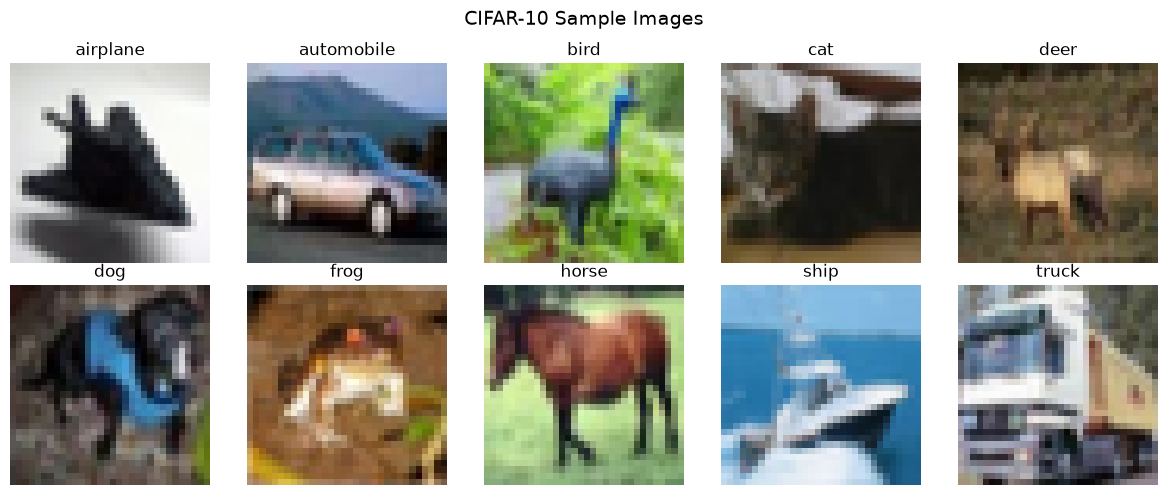

In [9]:

import matplotlib.pyplot as plt
import numpy as np

# CIFAR-10 class names
classes = train_dataset.classes

# Display one example from each class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_idx in range(10):

    # Find the first image belonging to this class
    image_idx = train_dataset.targets.index(class_idx)

    # Get image and label
    image, label = train_dataset[image_idx]

    # Convert from [C, H, W] to [H, W, C]
    image = image.permute(1, 2, 0).numpy()

    # Display image
    ax = axes[class_idx // 5, class_idx % 5]
    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle("CIFAR-10 Sample Images", fontsize=14)
plt.tight_layout()
plt.show()



## 1.3 Class Distribution Analysis

This section examines the number of images in each
CIFAR-10 class to determine whether the dataset
is balanced across all categories.


Class Distribution:
---------------------------------------------
airplane     | Train:  5000 | Test:  1000
automobile   | Train:  5000 | Test:  1000
bird         | Train:  5000 | Test:  1000
cat          | Train:  5000 | Test:  1000
deer         | Train:  5000 | Test:  1000
dog          | Train:  5000 | Test:  1000
frog         | Train:  5000 | Test:  1000
horse        | Train:  5000 | Test:  1000
ship         | Train:  5000 | Test:  1000
truck        | Train:  5000 | Test:  1000


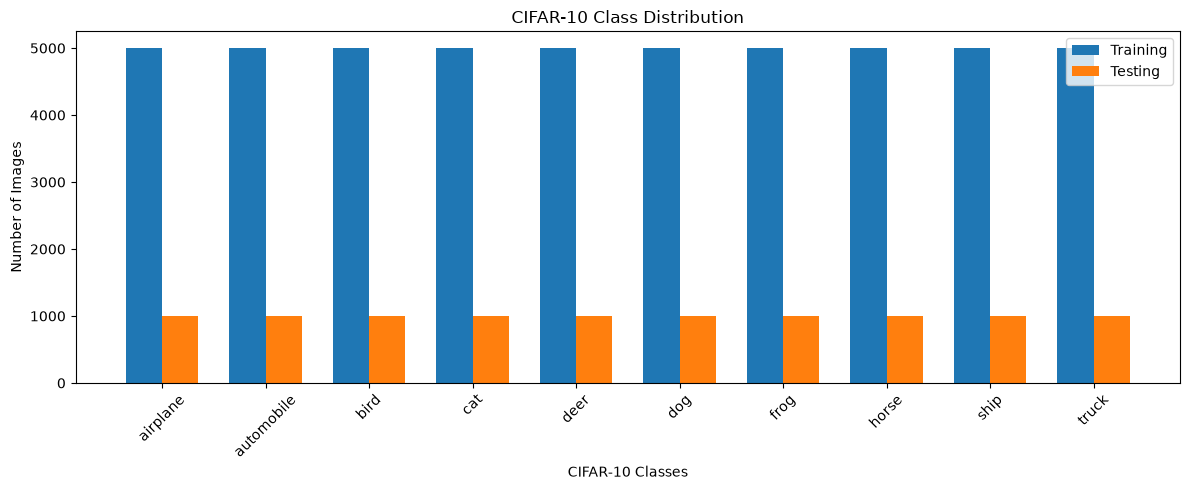

In [10]:

import numpy as np
import matplotlib.pyplot as plt

# Count images for each class
train_counts = np.bincount(
    train_dataset.targets, minlength=10
)

test_counts = np.bincount(
    test_dataset.targets, minlength=10
)

# Display the number of images
print("Class Distribution:")
print("-" * 45)

for i, class_name in enumerate(classes):
    print(
        f"{class_name:12s} | "
        f"Train: {train_counts[i]:5d} | "
        f"Test: {test_counts[i]:5d}"
    )

# Create bar chart
x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width/2,
    train_counts,
    width,
    label="Training"
)

plt.bar(
    x + width/2,
    test_counts,
    width,
    label="Testing"
)

plt.xlabel("CIFAR-10 Classes")
plt.ylabel("Number of Images")
plt.title("CIFAR-10 Class Distribution")
plt.xticks(x, classes, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()



## 1.4 Stratified Train/Validation Split

The original CIFAR-10 training dataset contains
50,000 images.

We split this dataset into 90% training and
10% validation data using stratified sampling.

Stratification preserves the class distribution,
ensuring that all 10 classes are equally represented.

A fixed random seed (42) is used for reproducibility.
The original test set remains unchanged.


In [11]:

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import numpy as np

# Original labels from CIFAR-10 training dataset
labels = np.array(train_dataset.targets)

# Indices for all 50,000 training images
indices = np.arange(len(train_dataset))

# Stratified split: 90% training, 10% validation
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.10,
    random_state=42,
    stratify=labels
)

# Create training and validation subsets
train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

# Verify dataset sizes
print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

# Verify class distribution
train_labels = labels[train_indices]
val_labels = labels[val_indices]

print("\nClass Distribution After Split:")
print("-" * 45)

for i, class_name in enumerate(classes):
    train_count = np.sum(train_labels == i)
    val_count = np.sum(val_labels == i)

    print(
        f"{class_name:12s} | "
        f"Train: {train_count:5d} | "
        f"Validation: {val_count:4d}"
    )


Training samples: 45000
Validation samples: 5000
Test samples: 10000

Class Distribution After Split:
---------------------------------------------
airplane     | Train:  4500 | Validation:  500
automobile   | Train:  4500 | Validation:  500
bird         | Train:  4500 | Validation:  500
cat          | Train:  4500 | Validation:  500
deer         | Train:  4500 | Validation:  500
dog          | Train:  4500 | Validation:  500
frog         | Train:  4500 | Validation:  500
horse        | Train:  4500 | Validation:  500
ship         | Train:  4500 | Validation:  500
truck        | Train:  4500 | Validation:  500



## 1.5 Data Normalization

We compute channel-wise mean and standard deviation
using only the training subset.

The same normalization parameters will be applied
to training, validation, and test images to avoid
data leakage and ensure consistent preprocessing.


In [12]:

from torch.utils.data import DataLoader

# Temporary DataLoader for computing statistics
stats_loader = DataLoader(
    train_subset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
total_pixels = 0

for images, labels_batch in stats_loader:
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sum_sq += (images ** 2).sum(dim=(0, 2, 3))
    total_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / total_pixels
std = torch.sqrt(
    channel_sum_sq / total_pixels - mean ** 2
)

print("Training mean:", mean)
print("Training std:", std)


Training mean: tensor([0.4911, 0.4821, 0.4464])
Training std: tensor([0.2469, 0.2434, 0.2616])


In [13]:

from torchvision import transforms
from torchvision.datasets import CIFAR10
from torch.utils.data import Subset

# Normalization transform
normalized_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean.tolist(),
        std=std.tolist()
    )
])

# Load the existing datasets with normalization
normalized_train_full = CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=normalized_transform
)

normalized_test = CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=normalized_transform
)

# Reuse exactly the same indices
train_final = Subset(normalized_train_full, train_indices)
val_final = Subset(normalized_train_full, val_indices)
test_final = normalized_test

print("Training:", len(train_final))
print("Validation:", len(val_final))
print("Testing:", len(test_final))


Training: 45000
Validation: 5000
Testing: 10000


In [14]:

from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_final,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify one batch
images, labels = next(iter(train_loader))

print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)
print("Image dtype:", images.dtype)


Batch images shape: torch.Size([64, 3, 32, 32])
Batch labels shape: torch.Size([64])
Image dtype: torch.float32



## 1.6 Final Preprocessing Verification

This section verifies that the normalized training
dataset has approximately zero channel-wise mean
and unit standard deviation.

It also verifies that the training, validation,
and test datasets contain the expected samples.


In [15]:

# Verify normalization using the complete training set
channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
total_pixels = 0

for images_batch, _ in train_loader:
    channel_sum += images_batch.sum(dim=(0, 2, 3))
    channel_sum_sq += (images_batch ** 2).sum(dim=(0, 2, 3))
    total_pixels += images_batch.shape[0] * 32 * 32

verified_mean = channel_sum / total_pixels
verified_std = torch.sqrt(
    channel_sum_sq / total_pixels - verified_mean ** 2
)

print("Normalized training mean:", verified_mean)
print("Normalized training std:", verified_std)

print("\nDataset sizes:")
print("Training:", len(train_final))
print("Validation:", len(val_final))
print("Test:", len(test_final))

# Final checks
assert len(train_final) == 45000
assert len(val_final) == 5000
assert len(test_final) == 10000

assert set(train_indices).isdisjoint(set(val_indices))

assert torch.allclose(
    verified_mean, torch.zeros(3), atol=1e-4
)

assert torch.allclose(
    verified_std, torch.ones(3), atol=1e-4
)

print("\nAll preprocessing checks passed!")


Normalized training mean: tensor([ 1.4227e-07,  5.4792e-07, -4.8415e-08])
Normalized training std: tensor([1.0000, 1.0000, 1.0000])

Dataset sizes:
Training: 45000
Validation: 5000
Test: 10000

All preprocessing checks passed!



## 1.7 Reproducibility and Group Handoff

We save the exact training and validation indices
and normalization parameters to ensure that the
MLP and CNN models use identical data partitions
and preprocessing settings.


In [16]:

import json
from pathlib import Path

# Create a folder for shared configuration files
config_dir = Path("config")
config_dir.mkdir(exist_ok=True)

# Save exact dataset indices
np.savez(
    config_dir / "split_indices.npz",
    train_indices=train_indices,
    val_indices=val_indices
)

# Save preprocessing parameters
config = {
    "dataset": "CIFAR-10",
    "random_state": 42,
    "training_samples": 45000,
    "validation_samples": 5000,
    "test_samples": 10000,
    "batch_size": BATCH_SIZE,
    "mean": mean.tolist(),
    "std": std.tolist(),
    "classes": classes
}

with open(
    config_dir / "preprocessing_config.json",
    "w"
) as file:
    json.dump(config, file, indent=4)

print("Configuration files saved successfully!")
print("Files:")
print(config_dir / "split_indices.npz")
print(config_dir / "preprocessing_config.json")


Configuration files saved successfully!
Files:
config\split_indices.npz
config\preprocessing_config.json



## 1.8 Configuration Verification

This section verifies that the saved preprocessing
configuration and dataset indices can be reloaded
correctly for reproducible experiments.


In [17]:

import json
import numpy as np

# Load saved dataset indices
saved_indices = np.load("config/split_indices.npz")

saved_train = saved_indices["train_indices"]
saved_val = saved_indices["val_indices"]

# Load saved preprocessing configuration
with open("config/preprocessing_config.json", "r") as file:
    saved_config = json.load(file)

# Verify saved values
assert np.array_equal(saved_train, train_indices)
assert np.array_equal(saved_val, val_indices)

assert len(saved_train) == 45000
assert len(saved_val) == 5000

assert np.allclose(saved_config["mean"], mean.numpy())
assert np.allclose(saved_config["std"], std.numpy())

print("Training indices:", len(saved_train))
print("Validation indices:", len(saved_val))
print("Saved mean:", saved_config["mean"])
print("Saved std:", saved_config["std"])
print("Batch size:", saved_config["batch_size"])

print("\nAll configuration checks passed!")


Training indices: 45000
Validation indices: 5000
Saved mean: [0.4911373257637024, 0.4821110665798187, 0.44644901156425476]
Saved std: [0.246869295835495, 0.24343018233776093, 0.261603444814682]
Batch size: 64

All configuration checks passed!


In [18]:

from data_preparation import get_cifar10_loaders

# Load datasets using the shared module
train_loader_shared, val_loader_shared, test_loader_shared = (
    get_cifar10_loaders()
)

# Check dataset sizes
print("Training:", len(train_loader_shared.dataset))
print("Validation:", len(val_loader_shared.dataset))
print("Testing:", len(test_loader_shared.dataset))

# Check one batch
images, labels = next(iter(train_loader_shared))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("\nShared data preparation module works!")


Training: 45000
Validation: 5000
Testing: 10000

Batch image shape: torch.Size([64, 3, 32, 32])
Batch label shape: torch.Size([64])

Shared data preparation module works!


In [19]:

from pathlib import Path

Path("gitignore.txt").rename(".gitignore")

print(".gitignore file created successfully!")


FileNotFoundError: [WinError 2] Sistem belirtilen dosyayı bulamıyor: 'gitignore.txt' -> '.gitignore'

In [20]:

from pathlib import Path

print(".gitignore exists:", Path(".gitignore").exists())
print("gitignore.txt exists:", Path("gitignore.txt").exists())


.gitignore exists: True
gitignore.txt exists: False


In [21]:

from pathlib import Path

print("Current folder:", Path.cwd())
print(".gitignore exists:", Path(".gitignore").exists())
print("gitignore.txt exists:", Path("gitignore.txt").exists())

if Path(".gitignore").exists():
    print("File location:", Path(".gitignore").resolve())


Current folder: C:\Users\user\Documents\GitHub\CIFAR10-Image-Classification
.gitignore exists: True
gitignore.txt exists: False
File location: C:\Users\user\Documents\GitHub\CIFAR10-Image-Classification\.gitignore


In [22]:
import torch
from torch import nn
from copy import deepcopy

torch.manual_seed(42)

train_loader = train_loader_shared
val_loader = val_loader_shared

# each image has 32 × 32 × 3 = 3072 values
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3072, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001)

best_accuracy = -1
best_weights = deepcopy(mlp.state_dict())

for epoch in range(10):

    # train the model using batches of images
    mlp.train()
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = mlp(images)
        loss = loss_function(outputs, labels)

        loss.backward()
        optimizer.step()

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # Check validation accuracy without updating the model
    mlp.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = mlp(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    train_accuracy = train_correct / train_total
    val_accuracy = val_correct / val_total

    # Keep a copy whenever validation accuracy improves
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_weights = deepcopy(mlp.state_dict())

    print(
        f"Epoch {epoch + 1}: "
        f"Training = {train_accuracy:.2%}, "
        f"Validation = {val_accuracy:.2%}"
    )

# Restore and save the best model
mlp.load_state_dict(best_weights)
mlp.eval()
torch.save(mlp.state_dict(), "mlp_weights.pth")

print(f"\nBest validation accuracy: {best_accuracy:.2%}")

C:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\cuda\__init__.py:484: UserWarning: Found GPU0 NVIDIA GeForce RTX 5070 Ti which is of compute capability (CC) 12.0.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 5.0 which supports hardware CC >=5.0,<6.0 except {5.3}
- 6.0 which supports hardware CC >=6.0,<7.0 except {6.2}
- 6.1 which supports hardware CC >=6.1,<7.0 except {6.2}
- 7.0 which supports hardware CC >=7.0,<8.0 except {7.2}
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0 except {8.7}
- 8.6 which supports hardware CC >=8.6,<9.0 except {8.7}
- 9.0 which supports hardware CC >=9.0,<10.0
Your installed torch==2.14.1+cu126 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 13.0 use pip install torch==2.14.1 --index-url https://download.pytorch.org/whl/cu130
  For CUDA 13.2 use pip install tor

Epoch 1: Training = 41.14%, Validation = 45.14%
Epoch 2: Training = 47.64%, Validation = 47.00%
Epoch 3: Training = 50.65%, Validation = 48.60%
Epoch 4: Training = 52.92%, Validation = 48.32%
Epoch 5: Training = 55.17%, Validation = 48.98%
Epoch 6: Training = 56.72%, Validation = 50.36%
Epoch 7: Training = 57.98%, Validation = 51.48%
Epoch 8: Training = 59.06%, Validation = 50.08%
Epoch 9: Training = 60.48%, Validation = 49.80%
Epoch 10: Training = 61.32%, Validation = 49.82%

Best validation accuracy: 51.48%


# CNN model

In [23]:
import torch
import torch.nn as nn
import torch.optim as optim

class CIFAR10_CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Input: 3 x 32 x 32
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 x 16 x 16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 64 x 8 x 8

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 128 x 4 x 4
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_model = CIFAR10_CNN().to(device)
print(cnn_model)
print("Using device:", device)

CIFAR10_CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Using device: cpu


In [24]:
device = torch.device("cpu")
cnn_model = cnn_model.to(device)

print("Using device:", device)

Using device: cpu


In [25]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

num_epochs = 10

cnn_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):
    # Training
    cnn_model.train()
    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_total += loss.item() * batch_size
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_total / train_total
    train_acc = 100.0 * train_correct / train_total

    # Validation
    cnn_model.eval()
    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_total += loss.item() * batch_size
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_total / val_total
    val_acc = 100.0 * val_correct / val_total

    cnn_history["train_loss"].append(train_loss)
    cnn_history["val_loss"].append(val_loss)
    cnn_history["train_accuracy"].append(train_acc)
    cnn_history["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_acc:.2f}%"
    )

Epoch [1/10] Train Loss: 1.4238 | Train Accuracy: 48.45% | Validation Loss: 1.1128 | Validation Accuracy: 60.54%
Epoch [2/10] Train Loss: 1.0033 | Train Accuracy: 64.59% | Validation Loss: 0.8747 | Validation Accuracy: 69.22%
Epoch [3/10] Train Loss: 0.8244 | Train Accuracy: 71.25% | Validation Loss: 0.7559 | Validation Accuracy: 73.28%
Epoch [4/10] Train Loss: 0.7071 | Train Accuracy: 75.25% | Validation Loss: 0.7712 | Validation Accuracy: 72.74%
Epoch [5/10] Train Loss: 0.6152 | Train Accuracy: 78.44% | Validation Loss: 0.7380 | Validation Accuracy: 74.34%
Epoch [6/10] Train Loss: 0.5385 | Train Accuracy: 80.97% | Validation Loss: 0.6989 | Validation Accuracy: 75.30%
Epoch [7/10] Train Loss: 0.4639 | Train Accuracy: 83.64% | Validation Loss: 0.6869 | Validation Accuracy: 76.70%
Epoch [8/10] Train Loss: 0.4057 | Train Accuracy: 85.58% | Validation Loss: 0.7792 | Validation Accuracy: 75.32%
Epoch [9/10] Train Loss: 0.3530 | Train Accuracy: 87.28% | Validation Loss: 0.7387 | Validation 

In [34]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    cnn_model.parameters(),
    lr=0.0003,
    weight_decay=0.005
)

print("Optimizer configured successfully.")

Optimizer configured successfully.


In [35]:
import importlib
import data_preparation

importlib.reload(data_preparation)

train_loader, val_loader, test_loader = (
    data_preparation.get_cifar10_loaders(
        project_dir=r"C:\Users\user\CIFAR10",
        download=False
    )
)

print("Training:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Test:", len(test_loader.dataset))

Training: 45000
Validation: 5000
Test: 10000


In [36]:
num_epochs = 25
patience = 5

best_val_loss = float("inf")
best_val_accuracy = 0.0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

model_path = r"C:\Users\user\CIFAR10\cnn_cifar10_regularized.pth"

for epoch in range(num_epochs):

    # Training phase
    cnn_model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_accuracy = 100.0 * train_correct / train_total

    # Validation phase
    cnn_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100.0 * val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

    # Save the best model by validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        epochs_without_improvement = 0

        torch.save(cnn_model.state_dict(), model_path)
        print("  Best model saved.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping after epoch {epoch + 1}.")
        break

print("\nTraining finished.")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy at best loss: {best_val_accuracy:.2f}%")
print("Best model saved to:", model_path)

Epoch [1/25] Train Loss: 1.5794 | Train Accuracy: 42.36% | Validation Loss: 1.3023 | Validation Accuracy: 52.92%
  Best model saved.
Epoch [2/25] Train Loss: 1.2378 | Train Accuracy: 55.59% | Validation Loss: 1.0850 | Validation Accuracy: 61.58%
  Best model saved.
Epoch [3/25] Train Loss: 1.0712 | Train Accuracy: 62.08% | Validation Loss: 0.9974 | Validation Accuracy: 64.46%
  Best model saved.
Epoch [4/25] Train Loss: 0.9546 | Train Accuracy: 66.27% | Validation Loss: 0.8897 | Validation Accuracy: 68.24%
  Best model saved.
Epoch [5/25] Train Loss: 0.8638 | Train Accuracy: 69.56% | Validation Loss: 0.8873 | Validation Accuracy: 68.16%
  Best model saved.
Epoch [6/25] Train Loss: 0.7874 | Train Accuracy: 72.17% | Validation Loss: 0.7868 | Validation Accuracy: 72.44%
  Best model saved.
Epoch [7/25] Train Loss: 0.7200 | Train Accuracy: 74.83% | Validation Loss: 0.8006 | Validation Accuracy: 71.68%
Epoch [8/25] Train Loss: 0.6613 | Train Accuracy: 76.89% | Validation Loss: 0.7598 | Vali

In [37]:
model_path = r"C:\Users\user\CIFAR10\cnn_cifar10_regularized.pth"

best_model = CIFAR10_CNN().to(device)
best_model.load_state_dict(
    torch.load(model_path, map_location=device)
)
best_model.eval()

#  test set evaluation
test_correct = 0
test_total = 0
test_loss_sum = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = best_model(images)
        loss = criterion(outputs, labels)

        test_loss_sum += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_accuracy = 100.0 * test_correct / test_total
test_loss = test_loss_sum / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct predictions: {test_correct}/{test_total}")

Test Loss: 0.7308
Test Accuracy: 75.80%
Correct predictions: 7580/10000
